In [48]:
import os
import sys
import numpy as np
import pandas as pd
sys.path.append("../utils")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# clean text data
import re
# import string
# from nltk.corpus import stopwords
# from nltk.stem import WordNetLemmatizer
# import nltk 

import spacy
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from wordcloud import WordCloud

# nltk.download("stopwords")
# nltk.download("wordnet")
# nltk.download("omw-1.4")


# text embeddings
from transformers import AutoTokenizer, AutoModel
from embedding_utils import extract_embeddings
from sentence_transformers import SentenceTransformer


# clustering
import hdbscan
from bertopic import BERTopic

# visualization
import matplotlib.pyplot as plt


In [49]:
df = pd.read_csv("../data/raw/corrected_data.csv")
df.head()

,bill_number,bill_url,bill_title,sponsor_name,sponsor_url,summary_title,summary_text,source_url,view_text_url,download_pdf_url,is_home_rule,municipality,num_cosponsors,cosponsors,history,path
0,H.4147,https://malegislature.gov/Bills/192/H4147,An Act providing technical education and econo...,"Harrington, Sheila C.",https://malegislature.gov/Legislators/Profile/...,An Act providing technical education and econo...,"(a) For purposes of this act, “autism spectrum...",https://malegislature.gov/Bills/192/H4147,https://malegislature.gov/Bills/192/H4147/Hous...,https://malegislature.gov/Bills/192/H4147.pdf,False,NaN,3,"[{'name': 'Lindsay N. Sabadosa', 'district': '...","[{'date': '9/30/2021', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...
1,S.1263,https://malegislature.gov/Bills/192/S1263,An Act relative to recovery homes,"Collins, Nick",https://malegislature.gov/Legislators/Profile/...,An Act relative to recovery homes,Nothwithstanding any special or general law to...,https://malegislature.gov/Bills/192/S1263,https://malegislature.gov/Bills/192/S1263/Sena...,https://malegislature.gov/Bills/192/S1263.pdf,False,NaN,0,[],"[{'date': '3/29/2021', 'branch': 'Senate', 'ac...",../../downloaded_legislation/state/MA/192nd/20...
2,H.3682,https://malegislature.gov/Bills/192/H3682,An Act amending the Medal of Liberty,"Murray, Brian W.",https://malegislature.gov/Legislators/Profile/...,An Act amending the Medal of Liberty,"Chapter 33 Section 67A of the General Laws, as...",https://malegislature.gov/Bills/192/H3682,https://malegislature.gov/Bills/192/H3682/Hous...,https://malegislature.gov/Bills/192/H3682.pdf,False,NaN,7,"[{'name': 'Michael J. Soter', 'district': '8th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...
3,SD.3464,https://malegislature.gov/Bills/192/SD3464,DVS Veteran Advisory Committee Interim Report,NaN,NaN,DVS Veteran Advisory Committee Interim Report,Report of the Department of Veterans’ Services...,https://malegislature.gov/Bills/192/SD3464,NaN,https://malegislature.gov/Bills/192/SD3464.pdf,False,NaN,0,[],"[{'date': '1/3/2023', 'branch': 'Senate', 'act...",../../downloaded_legislation/state/MA/192nd/20...
4,H.2990,https://malegislature.gov/Bills/192/H2990,An Act to encourage Massachusetts residency,"Livingstone, Jay D.",https://malegislature.gov/Legislators/Profile/...,An Act to encourage Massachusetts residency,SECTION 1. Chapter 65C of the General Laws is ...,https://malegislature.gov/Bills/192/H2990,https://malegislature.gov/Bills/192/H2990/Hous...,https://malegislature.gov/Bills/192/H2990.pdf,False,NaN,1,"[{'name': 'Carlos González', 'district': '10th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...


In [50]:
display(df.head())
print(df.shape)
df.info()

,bill_number,bill_url,bill_title,sponsor_name,sponsor_url,summary_title,summary_text,source_url,view_text_url,download_pdf_url,is_home_rule,municipality,num_cosponsors,cosponsors,history,path
0,H.4147,https://malegislature.gov/Bills/192/H4147,An Act providing technical education and econo...,"Harrington, Sheila C.",https://malegislature.gov/Legislators/Profile/...,An Act providing technical education and econo...,"(a) For purposes of this act, “autism spectrum...",https://malegislature.gov/Bills/192/H4147,https://malegislature.gov/Bills/192/H4147/Hous...,https://malegislature.gov/Bills/192/H4147.pdf,False,NaN,3,"[{'name': 'Lindsay N. Sabadosa', 'district': '...","[{'date': '9/30/2021', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...
1,S.1263,https://malegislature.gov/Bills/192/S1263,An Act relative to recovery homes,"Collins, Nick",https://malegislature.gov/Legislators/Profile/...,An Act relative to recovery homes,Nothwithstanding any special or general law to...,https://malegislature.gov/Bills/192/S1263,https://malegislature.gov/Bills/192/S1263/Sena...,https://malegislature.gov/Bills/192/S1263.pdf,False,NaN,0,[],"[{'date': '3/29/2021', 'branch': 'Senate', 'ac...",../../downloaded_legislation/state/MA/192nd/20...
2,H.3682,https://malegislature.gov/Bills/192/H3682,An Act amending the Medal of Liberty,"Murray, Brian W.",https://malegislature.gov/Legislators/Profile/...,An Act amending the Medal of Liberty,"Chapter 33 Section 67A of the General Laws, as...",https://malegislature.gov/Bills/192/H3682,https://malegislature.gov/Bills/192/H3682/Hous...,https://malegislature.gov/Bills/192/H3682.pdf,False,NaN,7,"[{'name': 'Michael J. Soter', 'district': '8th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...
3,SD.3464,https://malegislature.gov/Bills/192/SD3464,DVS Veteran Advisory Committee Interim Report,NaN,NaN,DVS Veteran Advisory Committee Interim Report,Report of the Department of Veterans’ Services...,https://malegislature.gov/Bills/192/SD3464,NaN,https://malegislature.gov/Bills/192/SD3464.pdf,False,NaN,0,[],"[{'date': '1/3/2023', 'branch': 'Senate', 'act...",../../downloaded_legislation/state/MA/192nd/20...
4,H.2990,https://malegislature.gov/Bills/192/H2990,An Act to encourage Massachusetts residency,"Livingstone, Jay D.",https://malegislature.gov/Legislators/Profile/...,An Act to encourage Massachusetts residency,SECTION 1. Chapter 65C of the General Laws is ...,https://malegislature.gov/Bills/192/H2990,https://malegislature.gov/Bills/192/H2990/Hous...,https://malegislature.gov/Bills/192/H2990.pdf,False,NaN,1,"[{'name': 'Carlos González', 'district': '10th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...


(68585, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68585 entries, 0 to 68584
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   bill_number       68585 non-null  object
 1   bill_url          68585 non-null  object
 2   bill_title        68585 non-null  object
 3   sponsor_name      46547 non-null  object
 4   sponsor_url       45765 non-null  object
 5   summary_title     68585 non-null  object
 6   summary_text      65451 non-null  object
 7   source_url        68585 non-null  object
 8   view_text_url     61252 non-null  object
 9   download_pdf_url  68585 non-null  object
 10  is_home_rule      68585 non-null  bool  
 11  municipality      3963 non-null   object
 12  num_cosponsors    68585 non-null  int64 
 13  cosponsors        68585 non-null  object
 14  history           68336 non-null  object
 15  path              68585 non-null  object
dtypes: bool(1), int64(1), object(14)
memory usage:

In [51]:
# PROBLEM 1
# Summary texts are not unique!
# SOME TExts can be replaced with nan val
df.summary_text.value_counts()

summary_text
Text is available in House Clerk's office ...                                                                                                                                              529
Text is available in the House Clerk's Office ...                                                                                                                                          231
Ordered, That the committee on Environment, Natural Resources and Agriculture be authorized to sit during a recess of the General Court to make an investigation and study of House ...     49
SECTION 1. Notwithstanding sections 32 to 37, inclusive, of chapter 7C of the General Laws or any other general or special law to the contrary, the commissioner of capital asset ...       46
Ordered, That the committee on State Administration and Regulatory Oversight be authorized to sit during a recess of the General Court to make an investigation and study of House ...      35
                                

In [52]:
df.summary_text.value_counts()[:30]

summary_text
Text is available in House Clerk's office ...                                                                                                                                              529
Text is available in the House Clerk's Office ...                                                                                                                                          231
Ordered, That the committee on Environment, Natural Resources and Agriculture be authorized to sit during a recess of the General Court to make an investigation and study of House ...     49
SECTION 1. Notwithstanding sections 32 to 37, inclusive, of chapter 7C of the General Laws or any other general or special law to the contrary, the commissioner of capital asset ...       46
Ordered, That the committee on State Administration and Regulatory Oversight be authorized to sit during a recess of the General Court to make an investigation and study of House ...      35
Text is available in the office 

In [53]:
placeholder_phrases = [
    "Text is available in the House Clerk's Office",
    "Text is available in House Clerk's office",
    "Text is available in the office of the Clerk of the House ... ",
    "Text is available in the office of the House Clerk ..."

    "",
    "5"
]

df['summary_text_clean'] = df['summary_text'].apply(
    lambda x: np.nan if any(phrase.lower() in str(x).lower() for phrase in placeholder_phrases) else x

)

In [54]:
df.summary_text_clean.value_counts()

summary_text_clean
Ordered, That the committee on Environment, Natural Resources and Agriculture be authorized to sit during a recess of the General Court to make an investigation and study of House ...        49
SECTION 1. Notwithstanding sections 32 to 37, inclusive, of chapter 7C of the General Laws or any other general or special law to the contrary, the commissioner of capital asset ...          46
Ordered, That the committee on State Administration and Regulatory Oversight be authorized to sit during a recess of the General Court to make an investigation and study of House ...         35
Text is available in the office of the Clerk of the House ...                                                                                                                                  25
Ordered, That the committee on Children, Families and Persons with Disabilities be authorized to sit during a recess of the General Court to make an investigation and study of ...            23
           

In [55]:
df['summary_title_clean'] = df['summary_title'].apply(
    lambda x: np.nan if any(phrase.lower() in str(x).lower() for phrase in placeholder_phrases) else x

)
df.summary_title_clean.value_counts()[:30]

summary_title_clean
Study Order                                                                                                                                                 305
Extension Order - Public Service                                                                                                                             45
Extension Order - Transportation                                                                                                                             38
Extension Order - Labor and Workforce Development                                                                                                            33
An Act financing improvements to municipal roads and bridges                                                                                                 32
An Act concerning the safety of school children embarking and disembarking school buses                                                                      31
An Act relative to h

In [56]:
# Drop NaNs and duplicates
df_topic = df.dropna(subset=['summary_title_clean']).drop_duplicates(subset=['summary_title_clean'])
len(df_topic)

37113

In [57]:
df_topic["summary_title_clean"].isna().sum( )

np.int64(0)

In [ ]:
# Load spaCy English model with NER and parser disabled for speed
nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])

custom_stopwords = set([
    "section", "chapter", "general", "laws", "hereby", "amended", "insert", "enact",
    "enactment", "law", "legislation", "act", "resolve", "order", "committee", "bill",
    "house", "senate", "commonwealth", "public", "private", "regulation", "statute",
    "effective", "provision", "subsection", "notwithstanding", "pursuant", "authorized",
    "office", "duty", "power", "authority", "text", "available", "clerk", "authorized",
    "recess", "investigation", "study", "authorized", "sitting", "office", "provide",
    "shall",  "state", "amend", "official", "edition", 
    "insert", "follow", "paragraph", "clause", "department", "relative",
    "massachusetts", "submit", "", "establish",
        "leave",     # very common, ambiguous
    "sick",      # procedural in employee/sick leave laws
    "bank",      # often just "sick leave bank"
    "employee",  # generic term across labor bills
    "fiscal",    # procedural, not topically defining
    "fund",      # generic
    "year",      # always present in budget/timing
    "commission",# too procedural, like “committee”
    "inspection",# structural
    "service",   # too vague
    "item",      # budget structure
    "county",    # geographical, not thematic
    "trust"      # legal term, often in estate/tax docs
])
stopwords = ENGLISH_STOP_WORDS.union(custom_stopwords)


In [59]:
def preprocess(text):
    if pd.isnull(text):
        return ""
    doc = nlp(text.lower())
    tokens = [
        token.lemma_ for token in doc
        if token.is_alpha and not token.is_stop and token.lemma_ not in stopwords
    ]
    return " ".join(tokens)

# Apply preprocessing
df_topic["cleaned"] = df_topic["summary_title_clean"].apply(preprocess)


In [60]:
df_topic[['summary_title', 'cleaned']].head(10)

,summary_title,cleaned
0,An Act providing technical education and econo...,technical education economic opportunity citiz...
1,An Act relative to recovery homes,recovery home
2,An Act amending the Medal of Liberty,medal liberty
3,DVS Veteran Advisory Committee Interim Report,dvs veteran advisory interim report
4,An Act to encourage Massachusetts residency,encourage residency
5,An Act relative to establishing institutional ...,institutional partnership
6,An Act exempting zero-emission commercial vehi...,exempt zero emission commercial vehicle sale tax
7,An Act to expand membership opportunities in l...,expand membership opportunity local cultural c...
8,Resolve establishing a task force to study rac...,task force racial disparity home ownership red...
9,An Act to prevent the illegal possession and i...,prevent illegal possession illegal sale firearm


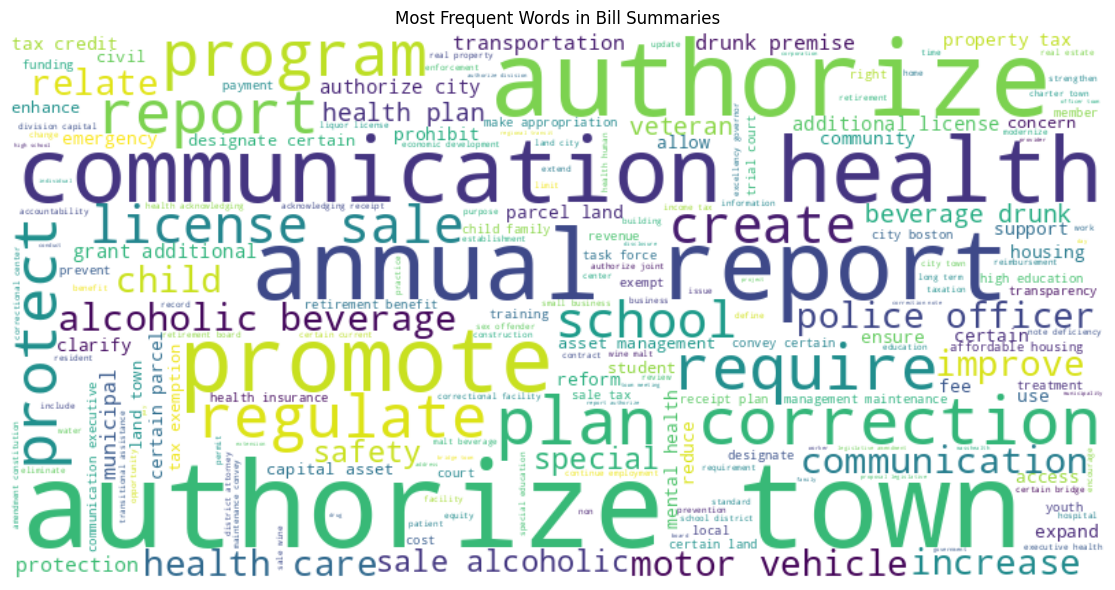

In [61]:
# Combine all bill summaries into one string
text_data = " ".join(df_topic['cleaned'].dropna()).lower()

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    # stopwords=stop_words,
    # max_words=100
).generate(text_data)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Most Frequent Words in Bill Summaries")
plt.tight_layout()
plt.show()


In [62]:
df_topic.shape

(37113, 19)

### BERTopic

In [63]:

texts = df_topic['cleaned'].dropna().tolist()
# del df_topic
# del df

In [64]:
len(texts)

37113

In [65]:

# topic_model = BERTopic()
# topics, probs = topic_model.fit_transform(texts)
# topic_model.get_topic_info()

hdbscan_model = hdbscan.HDBSCAN(min_cluster_size=20, metric='euclidean', cluster_selection_method='eom')
topic_model = BERTopic(hdbscan_model=hdbscan_model, top_n_words=10)

topics, probs = topic_model.fit_transform(texts)


In [66]:
pd.Series(topics).value_counts()
# 20 -  13551
# 20-10: 10775

-1      11020
 0        783
 1        306
 2        252
 3        239
        ...  
 443       20
 444       20
 445       20
 446       20
 447       20
Name: count, Length: 449, dtype: int64

In [69]:
topic_model.visualize_topics()

In [70]:
topic_model.visualize_barchart(top_n_topics=50)

In [71]:
from collections import Counter

# Combine top words from all topics
top_words_all = []
for topic_id in topic_model.get_topic_freq().Topic:
    if topic_id == -1:
        continue  # skip outliers
    topic_words = topic_model.get_topic(topic_id)
    top_words_all.extend([word for word, _ in topic_words])

# Count word frequencies
word_freq = Counter(top_words_all)
word_freq.most_common(30)

[('tax', 16),
 ('correction', 10),
 ('motor', 10),
 ('vehicle', 10),
 ('school', 10),
 ('insurance', 10),
 ('care', 9),
 ('health', 9),
 ('retirement', 9),
 ('education', 9),
 ('safety', 8),
 ('', 8),
 ('joint', 8),
 ('benefit', 7),
 ('plan', 7),
 ('exemption', 7),
 ('retiree', 7),
 ('construction', 7),
 ('child', 7),
 ('energy', 7),
 ('credit', 7),
 ('board', 7),
 ('reimbursement', 7),
 ('revenue', 7),
 ('election', 6),
 ('regional', 6),
 ('finance', 6),
 ('police', 6),
 ('officer', 6),
 ('communication', 6)]

In [75]:
topic_model2 = topic_model.reduce_topics(texts, nr_topics=30)

In [76]:
topic_model2.visualize_topics()

In [77]:
topic_model2.visualize_barchart(top_n_topics=50)

In [79]:
topic_model.get_topic(1) 


[('sexual', np.float64(0.08051110149090758)),
 ('crime', np.float64(0.07100191269680022)),
 ('victim', np.float64(0.062170785571045016)),
 ('justice', np.float64(0.05949850649884112)),
 ('assault', np.float64(0.05815352374424631)),
 ('domestic', np.float64(0.05515997363783616)),
 ('violence', np.float64(0.052645491906346015)),
 ('juvenile', np.float64(0.04883335628025463)),
 ('abuse', np.float64(0.046711784668947515)),
 ('harassment', np.float64(0.04576480922263006)),
 ('criminal', np.float64(0.031945540472757813)),
 ('hate', np.float64(0.029862125673416454)),
 ('offense', np.float64(0.029659214985214396)),
 ('child', np.float64(0.02770189928928268)),
 ('parole', np.float64(0.027670807295237517)),
 ('violent', np.float64(0.02622140587217466)),
 ('protect', np.float64(0.02505395121944864)),
 ('probation', np.float64(0.024432648278249827)),
 ('courthouse', np.float64(0.023103778522577202)),
 ('survivor', np.float64(0.022758344916259776)),
 ('conviction', np.float64(0.022136645836190013))

### BERTopic + SentenceTransformer

In [ ]:
model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = model.encode(texts, show_progress_bar=True)
hdbscan_model = hdbscan.HDBSCAN(min_cluster_size=40, metric='euclidean', cluster_selection_method='eom')
topic_model = BERTopic(hdbscan_model=hdbscan_model, top_n_words=20)


topics, probs = topic_model.fit_transform(texts, embeddings)


In [57]:
pd.Series(topics).value_counts()

-1     2724
 0      434
 1      302
 2      281
 3      273
 4      245
 5      209
 6      183
 7      182
 8      173
 9      151
 10     151
 11     142
 12     141
 13     134
 14     129
 15     126
 16     124
 17     119
 18     115
 19     112
 20     110
 21     109
 22     102
 23      97
 24      93
 25      87
 26      85
 27      84
 28      76
 29      73
 30      73
 31      73
 32      72
 33      70
 34      59
 35      57
 36      56
 37      46
 38      45
 39      42
 40      41
Name: count, dtype: int64

In [55]:
topic_model.visualize_topics()

In [56]:
topic_model.visualize_barchart(top_n_topics=40)

### BERTopic + BertLegal

In [109]:
import torch

# Load LegalBERT
model_name = "nlpaueb/legal-bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)

# Create embeddings
def encode(texts, tokenizer, model, max_length=512):
    model.eval()
    encoded_input = tokenizer(texts, padding=True, truncation=True, max_length=max_length, return_tensors='pt')
    with torch.no_grad():
        model_output = model(**encoded_input)
    embeddings = model_output.last_hidden_state.mean(dim=1)  # Mean pooling
    return embeddings.cpu().numpy()


texts = df_topic["cleaned"].tolist()[:8000]
embeddings = []

batch_size = 32
for i in range(0, len(texts), batch_size):
    batch_texts = texts[i:i+batch_size]
    batch_embeddings = encode(batch_texts, tokenizer, model)
    embeddings.extend(batch_embeddings)
embeddings = np.array(embeddings)

In [ ]:
import torch

# tokenizer = AutoTokenizer.from_pretrained("nlpaueb/legal-bert-base-uncased")
# model = AutoModel.from_pretrained("nlpaueb/legal-bert-base-uncased")

embeddings2= extract_embeddings(texts, tokenizer, model)
embeddings2.shape


(8000, 768)

In [144]:
from sklearn.metrics.pairwise import cosine_similarity

# Subset a few rows to test
embeddings = np.array(embeddings)
sim = cosine_similarity(embeddings2, embeddings)
print(sim.mean())


0.83745784


In [145]:
# topic_model = BERTopic()
# topics, probs = topic_model.fit_transform(texts, np.array(embeddings))
# topic_model.get_topic_info()


hdbscan_model = hdbscan.HDBSCAN(min_cluster_size=30, metric='euclidean', cluster_selection_method='eom')
topic_model = BERTopic(hdbscan_model=hdbscan_model, top_n_words=20)

topics, probs = topic_model.fit_transform(texts, embeddings2)

In [147]:
topic_model.visualize_topics()

In [148]:
topic_model.visualize_barchart(top_n_topics=50)

### Other

In [ ]:
from sentence_transformers import SentenceTransformer


embedding_model = SentenceTransformer("nlpaueb/legal-bert-base-uncased")
topic_model = BERTopic(embedding_model=embedding_model)

topics, probs = topic_model.fit_transform(texts)
topic_model.visualize_topics()

In [ ]:
# # simple text cleaning
# stop_words = set(stopwords.words("english"))
# stop_words.update({
#     "section", "shall", "chapter", "subsection", "act", "bill", "general", "law", "state",
#     "amended", "inserted", "following", "paragraph", "clause", "legislation", "hereby", "department", "relative"
# })
# lemmatizer = WordNetLemmatizer()

# def clean_text(text: str) -> str:
#     if not isinstance(text, str):
#         return ""
    
#     # Lowercase
#     text = text.lower()
    
#     # Remove line breaks, tabs, extra whitespace
#     text = re.sub(r"[\r\n\t]+", " ", text)
        
#     # Remove punctuation
#     text = text.translate(str.maketrans("", "", string.punctuation))
    
#     # Remove numbers
#     text = re.sub(r"\d+", "", text)
    
#     # Tokenize and remove stopwords, lemmatize
#     tokens = text.split()
#     tokens = [lemmatizer.lemmatize(word) for word in tokens]
#     tokens = [word for word in tokens if word not in stop_words and len(word) > 2]

#     return " ".join(tokens)

# df["summary_text_clean"].apply(clean_text)


# # Combine all bill summaries into one string
# text_data = " ".join(df['clean_text'].dropna()).lower()

# wordcloud = WordCloud(
#     width=800,
#     height=400,
#     background_color='white',
#     stopwords=stop_words,
#     # max_words=100
# ).generate(text_data)

# plt.figure(figsize=(12, 6))
# plt.imshow(wordcloud, interpolation='bilinear')
# plt.axis('off')
# plt.title("Most Frequent Words in Bill Summaries")
# plt.tight_layout()
# plt.show()


0        purpose “autism spectrum disorder” meaning def...
1        nothwithstanding special contrary proposal rec...
2        appearing official edition inserting word acti...
3        report veterans’ service pursuant interim repo...
4                         striking inserting place thereof
                               ...                        
68580           inserting notwithstanding special contrary
68581       appearing official edition adding sale certain
68582    known may cited “the massachusetts trauma resp...
68583    second appearing official edition adding sentence
68584                                                     
Name: summary_text_clean, Length: 68585, dtype: object

In [9]:
tokenizer = AutoTokenizer.from_pretrained("nlpaueb/legal-bert-base-uncased")
model = AutoModel.from_pretrained("nlpaueb/legal-bert-base-uncased")

embeddings = extract_embeddings(list(df[df.is_home_rule]['clean_text']), 
                                    tokenizer, 
                                    model)

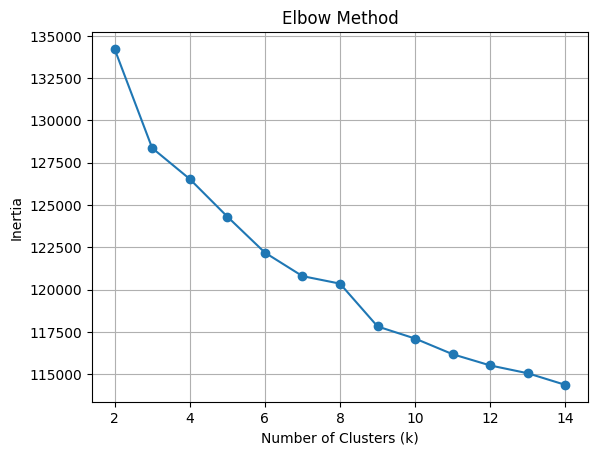

In [32]:
inertias = []
cluster_range = range(2, 15)

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(embeddings)
    inertias.append(kmeans.inertia_)

plt.plot(cluster_range, inertias, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.grid(True)
plt.show()


In [33]:
n_clusters = 9 
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
kmeans.fit(embeddings)
labels = kmeans.labels_

df_clustered = df.iloc[:8000]
df_clustered['topic'] = labels

for topic_id in range(n_clusters):
    print(f"\n=== Topic {topic_id} ===")
    for title in df_clustered[df_clustered['topic'] == topic_id]['title'].head(3):
        print(f"- {title}")


=== Topic 0 ===
- A report of the Lowell Regional Transit Authority (under Section 8(g) of Chapter 161B of the General Laws) submitting financial statements, supplemen...
- A communication from the Executive Office of Health and Human Services (see Section 16F of Chapter 6A of the General Laws) submitting the Massachuset...
- A report of the Worcester County District Attorney’s Office (under Section 99(R) of Chapter 272 of the General Laws) submitting a report relative to ...

=== Topic 1 ===
- Study Order
- Study Order
- Study Order

=== Topic 2 ===
- An Act to encourage Massachusetts residency
- An Act relative to establishing institutional public private partnerships
- An Act to expand membership opportunities in local cultural councils

=== Topic 3 ===
- An Act relative to the transparency of electronic weapons and devices
- An Act to improve child safety
- An Act improving housing opportunities

=== Topic 4 ===
- An Act exempting zero-emission commercial vehicles from the sales t

In [10]:
topic_model = BERTopic()

texts = df['clean_text'][:8000].dropna().tolist()

topics, probs = topic_model.fit_transform(texts)
topic_model.get_topic_info()

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


,Topic,Count,Name,Representation,Representative_Docs
0,-1,1881,-1_school_student_requirement_massachusetts,"[school, student, requirement, massachusetts, ...",[order authorizing joint committee transportat...
1,0,144,0_beverage_alcoholic_premise_additional,"[beverage, alcoholic, premise, additional, dru...",[authorizing town wareham grant additional lic...
2,1,136,1_study_order_interstate_noise,"[study, order, interstate, noise, confluence, ...","[study order, study order, study order]"
3,2,126,2_mental_behavioral_health_counselor,"[mental, behavioral, health, counselor, addict...","[student mental health, mental health child sc..."
4,3,92,3_commonwealth_song_official_growth,"[commonwealth, song, official, growth, governm...","[relating economic growth relief commonwealth,..."
...,...,...,...,...,...
207,206,11,206_immediate_need_recovery_covid,"[immediate, need, recovery, covid, jjpad, hpc,...","[immediate covid recovery need, immediate covi..."
208,207,11,207_alzheimers_dementia_caring_disease,"[alzheimers, dementia, caring, disease, adviso...",[establishing tax credit family caring elderly...
209,208,11,208_minority_enterprise_business_womenowned,"[minority, enterprise, business, womenowned, c...",[expand opportunity minority woman business en...
210,209,10,209_infrastructure_local_modernization_investment,"[infrastructure, local, modernization, investm...",[local energy investment infrastructure modern...


In [11]:
topic_model.visualize_topics()

In [12]:
from sentence_transformers import SentenceTransformer

# Load Legal-BERT model (HuggingFace name is correct here)
embedding_model = SentenceTransformer("nlpaueb/legal-bert-base-uncased")
topic_model = BERTopic(embedding_model=embedding_model)

topics, probs = topic_model.fit_transform(texts)
topic_model.visualize_topics()

No sentence-transformers model found with name nlpaueb/legal-bert-base-uncased. Creating a new one with mean pooling.


In [13]:
topic_model.visualize_barchart()